In [1]:
import pysvorbit
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
from backend import _solve_kepler

In [2]:
num_points = 10000
# Sky projected orbit plotter function
def get_sky_projected_orbit(a, e, i, omega, Omega, num_points):

    # Computes sky-projected coordinates (X, Y) from Keplerian elements. Angles (i, omega, Omega) should be in degrees.
    
    # Convert angles to radians
    i_rad = np.radians(i)
    omega_rad = np.radians(omega)
    Omega_rad = np.radians(Omega)
    
    # 1. Sample true anomalies across a full orbit
    nu = np.linspace(0, 2 * np.pi, num_points)
    
    # 2. Distance 'r' from the focus for an ellipse
    r = (a * (1 - e**2)) / (1 + e * np.cos(nu))
    
    # Position vectors in the intrinsic orbital plane
    x_prime = r * np.cos(nu)
    y_prime = r * np.sin(nu)
    
    # 3. Apply Thiele-Innes or standard rotation matrix combinations
    # X (East) and Y (North) positions projected on the plane of the sky
    X = x_prime * (np.cos(omega_rad) * np.sin(Omega_rad) + np.sin(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.sin(Omega_rad) + np.cos(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad))
        
    Y = x_prime * (np.cos(omega_rad) * np.cos(Omega_rad) - np.sin(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.cos(Omega_rad) - np.cos(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad))
        
    return X, Y



def sky_position_at_epoch(t, P, T, e, a, i, omega, Omega):
    """
    Model position on the sky at epoch(s) t, using the same projection as
    get_sky_projected_orbit(). 'a' in the units you want back (mas here);
    angles in degrees; t, T, P all in years.
    Returns (North, East) so it plots directly on your (x = North, y = East) axes.
    """
    t = np.atleast_1d(np.asarray(t, dtype=float))
 
    # Mean anomaly at each epoch
    M = 2 * np.pi * (((t - T) / P) % 1.0)
 
    # Eccentric anomaly from PySVOrbit's own Kepler solver (one epoch at a time)
    E = np.array([_solve_kepler(m, e) for m in M])
 
    # Safety check: _solve_kepler can occasionally diverge at very high e
    bad = np.abs(E - e * np.sin(E) - M) > 1e-6
    if bad.any():
        raise RuntimeError(f"_solve_kepler did not converge for epoch(s) {t[bad]}")
 
    # True anomaly and orbital radius
    nu = 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))
    r = a * (1 - e**2) / (1 + e * np.cos(nu))
    xp, yp = r * np.cos(nu), r * np.sin(nu)
 
    io, wo, Oo = np.radians([i, omega, Omega])
    East = xp * (np.cos(wo) * np.sin(Oo) + np.sin(wo) * np.cos(Oo) * np.cos(io)) + \
           yp * (-np.sin(wo) * np.sin(Oo) + np.cos(wo) * np.cos(Oo) * np.cos(io))
    North = xp * (np.cos(wo) * np.cos(Oo) - np.sin(wo) * np.sin(Oo) * np.cos(io)) + \
            yp * (-np.sin(wo) * np.cos(Oo) - np.cos(wo) * np.sin(Oo) * np.cos(io))
    return North, East


Position measures: 0
RV measures: 714, 615
Fitting 7 elements: ['P', 'T', 'e', 'w', 'K1', 'K2', 'V0']
Total observations: 1329 (npos=0, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0846e+06, final cost 2.1127e+06, first-order optimality 1.32e+03.
Degrees of freedom: 1322
Chi-squared: 4225328.6388, Reduced Chi-squared: 3196.1639
Jacobian shape: (1329, 7)
JTJ condition number: 9.98e+09
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['0.0000', '0.0000', '5878.5680', '45.5790']
RMS (Theta, rho, RV1, RV2): 0.0000, 0.0000, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.0000
W    :     0.0000
w    :   255.6900
i    :     0.0000

Initial Mass Estimates:
 Total mass (from a, P, π): 0.000 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.797844 solar masses
  M₁             = inf solar masses
  M₂          

/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:1076: RuntimeWarning: divide by zero encountered in scalar divide
  M_total = M12_sin3i / sin3_i
/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:1076: RuntimeWarning: divide by zero encountered in scalar divide
  M_total = M12_sin3i / sin3_i


PySVOrbit Fit Results:

P = 2.4363465775758453 ± 1.1958799229461468e-07
T = 2007.2595968758087 ± 2.6175515070371584e-07
e = 0.9768044159310214 ± 1.9113404594020215e-06
a = 0.0 ± 0.0
W = 0.0 ± 0.0
w = 255.73498043630923 ± 0.001628667215519835
i = 0.0 ± 0.0
K1 = 37.859096076995826 ± 0.000965443925081458
K2 = 57.08689811015508 ± 0.004886439461333401
V0 = 7.432899858971973 ± 0.00022791012019655646


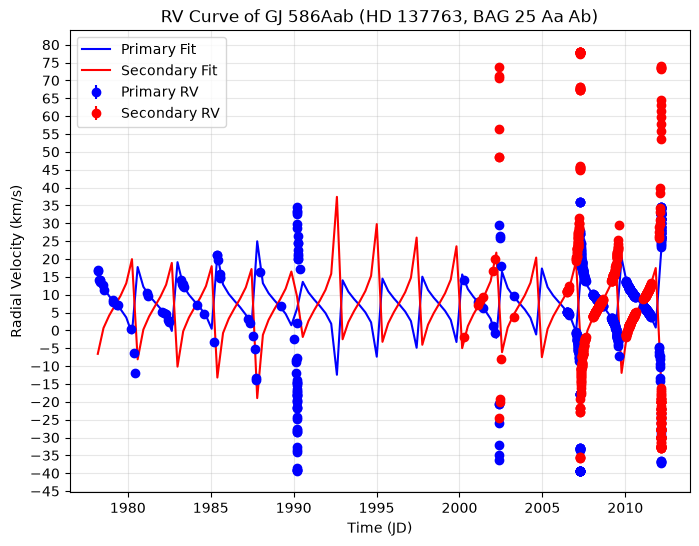

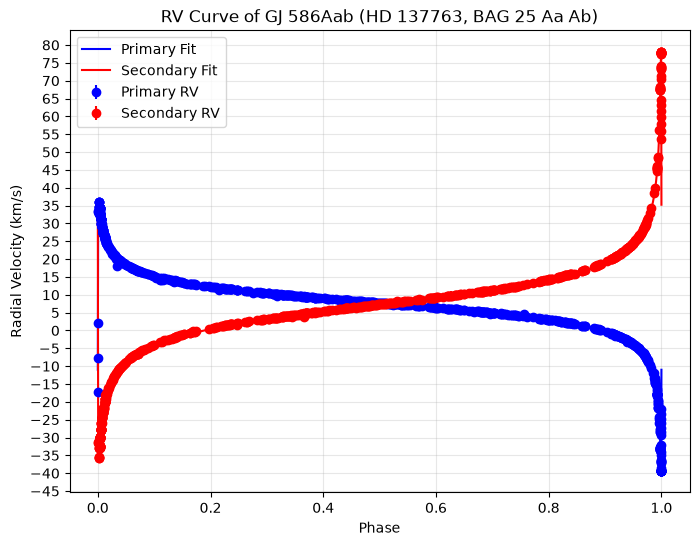

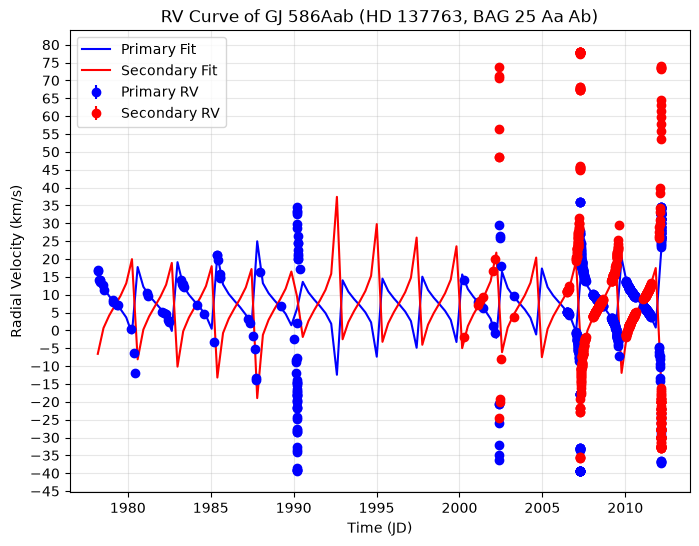

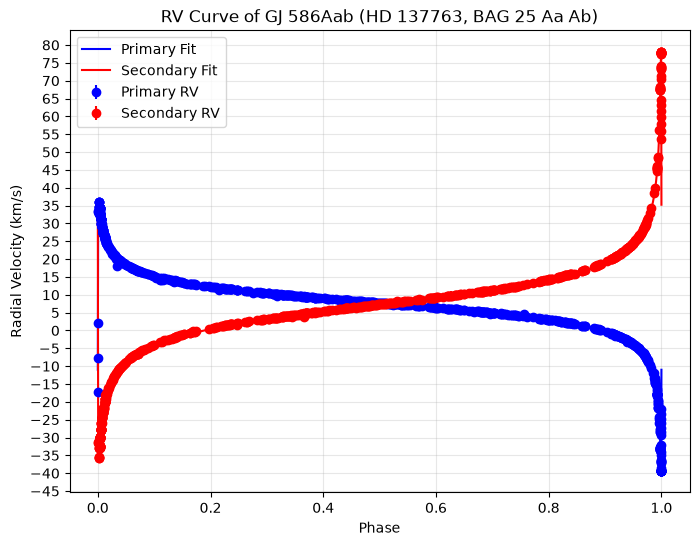

In [3]:
# Load the SOAR + Strass RV data and save its orbital elements to be plotted 
data_path = "Strass2013RV/GJ586A_StrassRV.inp"
#data_path = "test.inp"

pysvorbit.readinp(data_path)


# Uses scipy least_squares() to fit the orbit
pysvorbit.fitorb() 

pysvorbit.orbsave()   # writes <name>_output.csv to the working directory

pysvorbit.orbplot(ps=True) # plots fitted orbit and closes figs






print("PySVOrbit Fit Results:\n")
for name, value, error in zip(pysvorbit.orb.elname,
                              pysvorbit.orb.el,
                              pysvorbit.orb.elerr):
    print(f"{name} = {value} ± {error}")

P, T, e, a, W, w, i, K1, K2, V0 = pysvorbit.orb.el


Primary residual stdev = 1.102187234467898 km/s
Secondary residual stdev = 0.3446022464529951 km/s


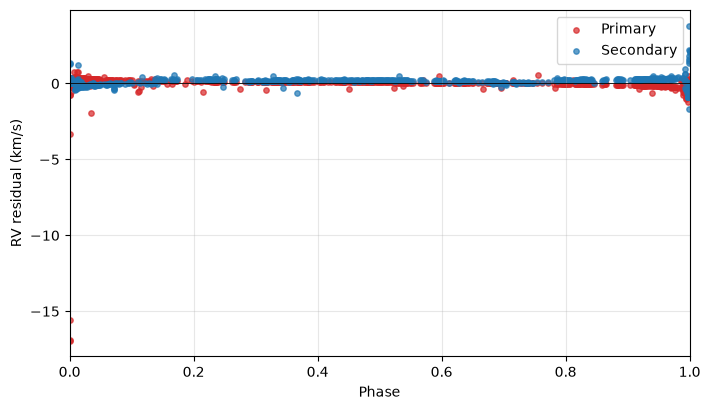

In [4]:
# Radial-velocity residual versus phase for the fit currently loaded.
# Phase 0 is periastron. Residual is observed velocity minus the model.
el = pysvorbit.orb.el

fig, ax = plt.subplots(figsize=(8, 4.5))
for rv, sources, component, color, label in (
    (pysvorbit.orb.rv1, pysvorbit.orb.rv1_source, 0, "C3", "Primary"),
    (pysvorbit.orb.rv2, pysvorbit.orb.rv2_source, 1, "C0", "Secondary"),
):
    if rv.size == 0:
        continue
    t = rv[:, 0]
    phase = np.mod(t - T, P) / P
    model = pysvorbit.eph(el, t, rv=True)[:, component]
    model = model + pysvorbit.rv_offset_for_points(sources, len(t))
    residual = rv[:, 1] - model
    print(f"{label} residual stdev = {np.std(residual)} km/s")
    ax.scatter(
        phase, residual, color=color, alpha=0.7, label=label, s=15,
    )

ax.axhline(0.0, color="k", lw=0.6)
ax.set_xlim(0, 1)
ax.set_xlabel("Phase")
ax.set_ylabel("RV residual (km/s)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


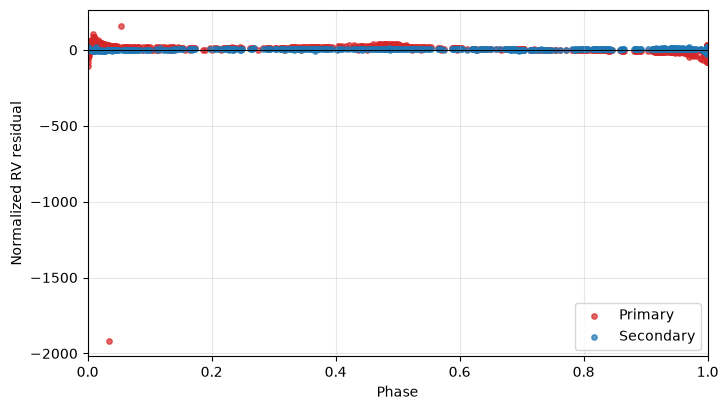

In [5]:
# Plot RV Normalized Residuals vs phase for the fit currently loaded.
# Phase 0 is periastron. Normalized residual is (observed - model) / quoted error.
el = pysvorbit.orb.el

fig, ax = plt.subplots(figsize=(8, 4.5))
for rv, sources, component, color, label in (
    (pysvorbit.orb.rv1, pysvorbit.orb.rv1_source, 0, "C3", "Primary"),
    (pysvorbit.orb.rv2, pysvorbit.orb.rv2_source, 1, "C0", "Secondary"),
):
    if rv.size == 0:
        continue
    t = rv[:, 0]
    phase = np.mod(t - T, P) / P
    model = pysvorbit.eph(el, t, rv=True)[:, component]
    model = model + pysvorbit.rv_offset_for_points(sources, len(t))
    normalized = (rv[:, 1] - model) / rv[:, 2]
    ax.scatter( phase, normalized, color=color, alpha=0.7, label=label, s=15)

ax.axhline(0.0, color="k", lw=0.6)
ax.axhline(1.0, color="k", lw=0.4, ls="--")
ax.axhline(-1.0, color="k", lw=0.4, ls="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Phase")
ax.set_ylabel("Normalized RV residual")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [6]:
rv_data_a = pysvorbit.orb.rv1
rv_data_b = pysvorbit.orb.rv2

t_rv_a = rv_data_a[:, 0]
rv_a = rv_data_a[:, 1]
rv_a_err = rv_data_a[:, 2]

t_rv_b = rv_data_b[:, 0]
rv_b = rv_data_b[:, 1]
rv_b_err = rv_data_b[:, 2]

In [7]:
print(np.std(rv_a_err))
print(np.std(rv_b_err))

0.09378818290193021
0.1256959984304028


In [8]:
print(pysvorbit.orb.obj.keys())

# RV rms error
print(pysvorbit.orb.obj["rms"][3])

orb = pysvorbit.orb
n = 2 * orb.obj["npos"] + orb.obj["nrv1"] + orb.obj["nrv2"]
dof = n - np.count_nonzero(orb.fixel)
chi2r = orb.obj["chi2"] / dof
print(f'Reduced Chi2 = {chi2r}')

dict_keys(['name', 'radeg', 'dedeg', 'npos', 'nrv1', 'nrv2', 'rms', 'chi2n', 'chi2', 'fname', 'parallax'])
0.2454377337074259
Reduced Chi2 = 3196.1638720249784


In [9]:
# Filter primary and secondary radial velocities on the normalized residual.
# Normalized residual is (observed - model) / quoted error.
# Fit the full list once, then n_clips times: measure each star's
# normalized-residual standard deviation, drop points beyond n_sigma
# of that standard deviation, and refit. The next pass uses the new fit.
# The file is reloaded first, so running this cell again starts from the full list.
n_sigma = 5

def residual_clip(el, n_sigma):
    kept = []
    for rv, sources, component, label in (
        (pysvorbit.orb.rv1, pysvorbit.orb.rv1_source, 0, "Primary"),
        (pysvorbit.orb.rv2, pysvorbit.orb.rv2_source, 1, "Secondary"),
    ):
        if rv.size == 0:
            print(f"{label}: no velocities")
            kept.append([])
            continue
        model = pysvorbit.eph(el, rv[:, 0], rv=True)[:, component]
        model = model + pysvorbit.rv_offset_for_points(sources, len(rv))
        normalized = (rv[:, 1] - model) / rv[:, 2]
        sigma = float(np.std(normalized))
        limit = n_sigma * sigma
        keep = np.abs(normalized) <= limit
        #print('-'*50)
        #print(f"{label} normalized residual stdev = {sigma}")
        #print(f"{label} {n_sigma}-sigma cut = {limit}")
        print(f"{label} kept {int(np.count_nonzero(keep))} of {len(normalized)}")
        #print('-'*50)
        kept.append(np.flatnonzero(keep).tolist())
    return kept

pysvorbit.readinp(data_path)
pysvorbit.fitorb()




orb = pysvorbit.orb
n = 2 * orb.obj["npos"] + orb.obj["nrv1"] + orb.obj["nrv2"]
dof = n - np.count_nonzero(orb.fixel)
initial_chi2r = orb.obj["chi2"] / dof
print(f"Initial reduced chi2 = {initial_chi2r}")
P, T, e, a, W, w, i, K1, K2, V0 = pysvorbit.orb.el


chi2r_list = []
counter = 0

while chi2r >= 1.5:
    # Returns a list of RV points that are filtered
    keep_rv1, keep_rv2 = residual_clip(pysvorbit.orb.el, n_sigma)

    # Stop the loop if nothing changes between iterations 
    if len(keep_rv1) == orb.obj["nrv1"] and len(keep_rv2) == orb.obj["nrv2"]:
        print("No points removed; stopping.")
        break

    # Refit the orbit based on the filtered RV points
    pysvorbit.restrict_points(rv1_keep=keep_rv1, rv2_keep=keep_rv2)
    pysvorbit.fitorb()
    plt.close('all')

    print('-'*50)
    # Update the number of degrees of freedom and reduced chi2
    n = 2 * orb.obj["npos"] + orb.obj["nrv1"] + orb.obj["nrv2"]
    dof = n - np.count_nonzero(orb.fixel)
    chi2r = orb.obj["chi2"] / dof
    chi2r_list.append(chi2r)
    counter += 1
    print(f"Reduced chi2 = {chi2r}, Iteration: {counter}")
    print('-'*50)
    




Position measures: 0
RV measures: 714, 615
Fitting 7 elements: ['P', 'T', 'e', 'w', 'K1', 'K2', 'V0']
Total observations: 1329 (npos=0, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0846e+06, final cost 2.1127e+06, first-order optimality 1.32e+03.
Degrees of freedom: 1322
Chi-squared: 4225328.6388, Reduced Chi-squared: 3196.1639
Jacobian shape: (1329, 7)
JTJ condition number: 9.98e+09
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['0.0000', '0.0000', '5878.5680', '45.5790']
RMS (Theta, rho, RV1, RV2): 0.0000, 0.0000, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.0000
W    :     0.0000
w    :   255.6900
i    :     0.0000

Initial Mass Estimates:
 Total mass (from a, P, π): 0.000 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.797844 solar masses
  M₁             = inf solar masses
  M₂          

/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:1076: RuntimeWarning: divide by zero encountered in scalar divide
  M_total = M12_sin3i / sin3_i


`xtol` termination condition is satisfied.
Function evaluations 5, initial cost 2.7621e+05, final cost 4.4169e+04, first-order optimality 2.05e+06.
Degrees of freedom: 1321
Chi-squared: 88337.9673, Reduced Chi-squared: 66.8720
Jacobian shape: (1328, 7)
JTJ condition number: 8.89e+09
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['0.0000', '0.0000', '102.2999', '25.0376']
RMS (Theta, rho, RV1, RV2): 0.0000, 0.0000, 0.0582, 0.1819

Initial Parameters (from input file):
P    :     2.4363
T    :  2007.2596
e    :     0.9768
a    :     0.0000
W    :     0.0000
w    :   255.7350
i    :     0.0000

Initial Mass Estimates:
 Total mass (from a, P, π): 0.000 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.774686 solar masses
  M₁             = inf solar masses
  M₂             = inf solar masses

Fitted Parameters and Errors:
P    :     2.4363 ± 0.0000
T    :  2007.2597 ± 0.0000
e    :     0.9761 ± 0.0000
w    :   255.7104 ± 0.0016



Filtered fit
P = 2.43624886135518 ± 4.1323149640271597e-07
T = 2007.2598171025088 ± 8.269488698539741e-07
e = 0.9758875373110746 ± 2.1318850830952273e-06
a = 0.0 ± 0.0
W = 0.0 ± 0.0
w = 255.58368955596194 ± 0.0016511717224633603
i = 0.0 ± 0.0
K1 = 37.81288430476084 ± 0.000958928860964774
K2 = 56.474511147234885 ± 0.0048648444720809664
V0 = 7.495221696673994 ± 0.00023711532462652665


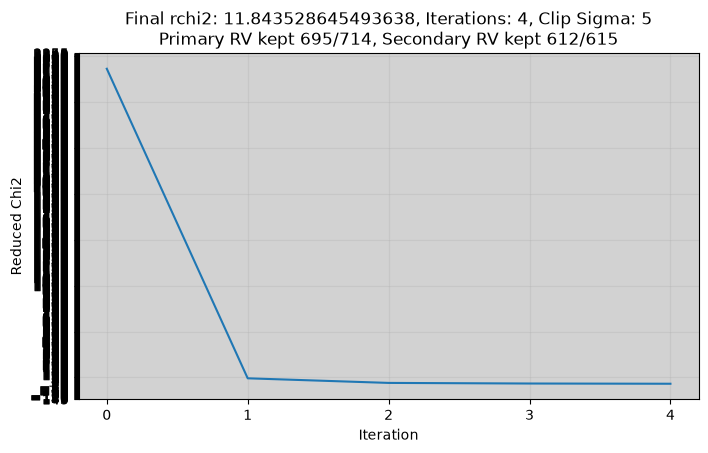

11.843528645493638


In [ ]:
print("\nFiltered fit")
for name, value, error in zip(pysvorbit.orb.elname, pysvorbit.orb.el, pysvorbit.orb.elerr):
    print(f"{name} = {value} ± {error}")




fig, ax = plt.subplots(figsize=(8, 4.5))
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_major_locator(MultipleLocator(250))

chi2r_plot = [initial_chi2r, *chi2r_list]
iterations_clip = np.arange(len(chi2r_plot))
ax.plot(iterations_clip, chi2r_plot)

ax.set_xlabel("Iteration")
ax.set_ylabel("Reduced Chi2")
ax.set_title(f"Final rchi2: {chi2r}, Iterations: {counter}, Clip Sigma: {n_sigma}\nPrimary RV kept {len(keep_rv1)}/{len(rv_data_a)}, Secondary RV kept {len(keep_rv2)}/{len(rv_data_b)}")
ax.grid(alpha=0.3)
plt.show()
print(chi2r)

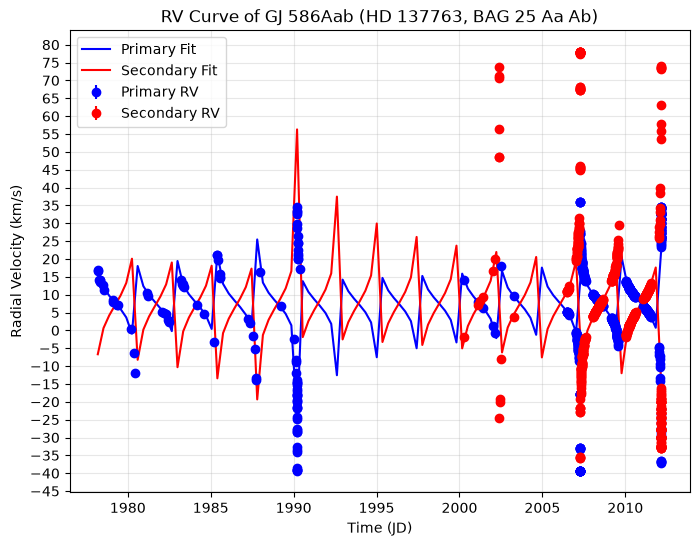

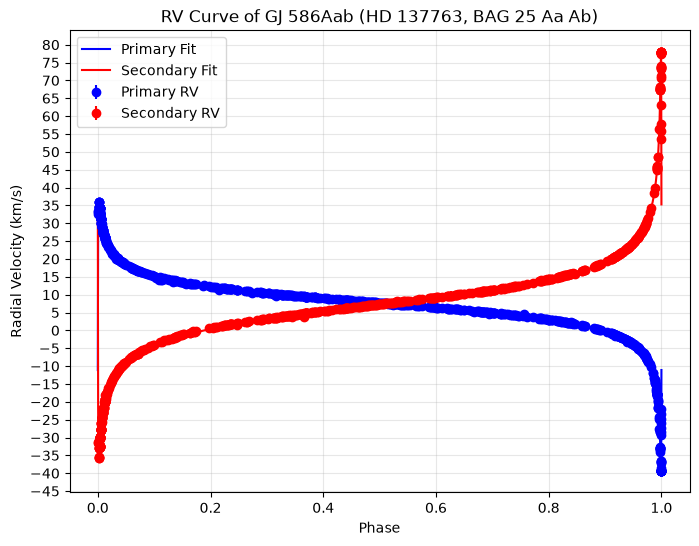

In [11]:
pysvorbit.orbplot(ps=True) # plots fitted orbit and closes figs

Primary residual stdev = 0.22919530327408177 km/s
Secondary residual stdev = 0.27456405719532506 km/s


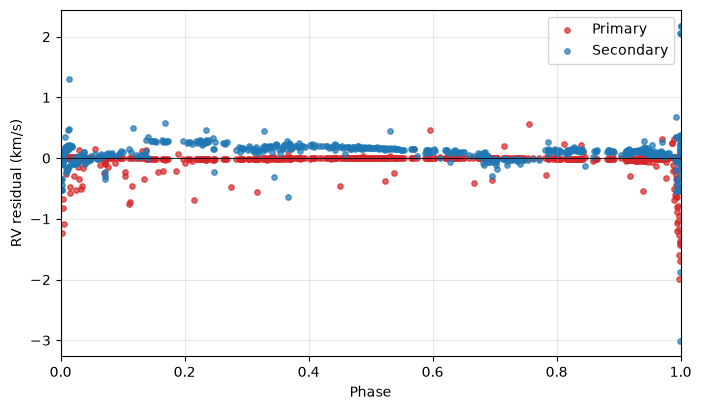

In [12]:
# Radial-velocity residual versus phase for the fit currently loaded.
# Phase 0 is periastron. Residual is observed velocity minus the model.
el = pysvorbit.orb.el

fig, ax = plt.subplots(figsize=(8, 4.5))
for rv, sources, component, color, label in (
    (pysvorbit.orb.rv1, pysvorbit.orb.rv1_source, 0, "C3", "Primary"),
    (pysvorbit.orb.rv2, pysvorbit.orb.rv2_source, 1, "C0", "Secondary"),
):
    if rv.size == 0:
        continue
    t = rv[:, 0]
    phase = np.mod(t - T, P) / P
    model = pysvorbit.eph(el, t, rv=True)[:, component]
    model = model + pysvorbit.rv_offset_for_points(sources, len(t))
    residual = rv[:, 1] - model
    print(f"{label} residual stdev = {np.std(residual)} km/s")
    ax.scatter(
        phase, residual, color=color, alpha=0.7, label=label, s=15,
    )

ax.axhline(0.0, color="k", lw=0.6)
ax.set_xlim(0, 1)
ax.set_xlabel("Phase")
ax.set_ylabel("RV residual (km/s)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


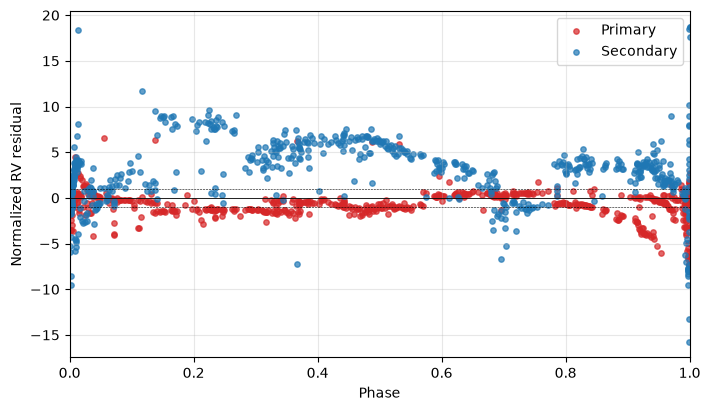

In [13]:
# Plot RV Normalized Residuals vs phase for the fit currently loaded.
# Phase 0 is periastron. Normalized residual is (observed - model) / quoted error.
el = pysvorbit.orb.el

fig, ax = plt.subplots(figsize=(8, 4.5))
for rv, sources, component, color, label in (
    (pysvorbit.orb.rv1, pysvorbit.orb.rv1_source, 0, "C3", "Primary"),
    (pysvorbit.orb.rv2, pysvorbit.orb.rv2_source, 1, "C0", "Secondary"),
):
    if rv.size == 0:
        continue
    t = rv[:, 0]
    phase = np.mod(t - T, P) / P
    model = pysvorbit.eph(el, t, rv=True)[:, component]
    model = model + pysvorbit.rv_offset_for_points(sources, len(t))
    normalized = (rv[:, 1] - model) / rv[:, 2]
    ax.scatter( phase, normalized, color=color, alpha=0.7, label=label, s=15)

ax.axhline(0.0, color="k", lw=0.6)
ax.axhline(1.0, color="k", lw=0.4, ls="--")
ax.axhline(-1.0, color="k", lw=0.4, ls="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Phase")
ax.set_ylabel("Normalized RV residual")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [14]:
# Final fit of the filtered velocities. Multiply every quoted error by
# sqrt(reduced chi2) of the filtered fit, then refit. The relative weights
# stay the same, so the orbit is unchanged and the reduced chi-squared
# becomes 1. The unscaled errors are kept, so running this cell again
# does not scale them a second time.
error_scale = np.sqrt(chi2r)
pysvorbit.orb.rv1[:, 2] = pysvorbit.orb.rv1[:, 2] * error_scale

pysvorbit.orb.rv2[:, 2] = pysvorbit.orb.rv2[:, 2] * error_scale

print(f"Error scale = {error_scale}")
pysvorbit.fitorb()
plt.close("all")

print("\nRescaled-error fit")
for name, value, error in zip(pysvorbit.orb.elname, pysvorbit.orb.el, pysvorbit.orb.elerr):
    print(f"{name} = {value} ± {error}")

orb = pysvorbit.orb
n = 2 * orb.obj["npos"] + orb.obj["nrv1"] + orb.obj["nrv2"]
dof = n - np.count_nonzero(orb.fixel)
chi2r_rescaled = orb.obj["chi2"] / dof
print(f"Reduced Chi2 = {chi2r_rescaled}")
P, T, e, a, W, w, i, K1, K2, V0 = pysvorbit.orb.el


Error scale = 3.4414428145028997
Fitting 7 elements: ['P', 'T', 'e', 'w', 'K1', 'K2', 'V0']
Total observations: 1307 (npos=0, nrv1=695, nrv2=612)
`xtol` termination condition is satisfied.
Function evaluations 2, initial cost 6.5000e+02, final cost 6.5000e+02, first-order optimality 1.02e+02.
Degrees of freedom: 1300
Chi-squared: 1300.0000, Reduced Chi-squared: 1.0000
Jacobian shape: (1307, 7)
JTJ condition number: 8.62e+09
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['0.0000', '0.0000', '0.2205', '1.8738']
RMS (Theta, rho, RV1, RV2): 0.0000, 0.0000, 0.0095, 0.1709

Initial Parameters (from input file):
P    :     2.4363
T    :  2007.2598
e    :     0.9759
a    :     0.0000
W    :     0.0000
w    :   255.5855
i    :     0.0000

Initial Mass Estimates:
 Total mass (from a, P, π): 0.000 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.803733 solar masses
  M₁             = inf solar masses
  M₂             = inf solar masse